<a href="https://colab.research.google.com/github/OmarLarios/diplomado-tecnicas-estadisticas/blob/main/apuntes/03_Variables_aleatorias_discretas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Variables aleatorias discretas

###Clase 3

**14 de noviembre del 2026**

In [1]:
import numpy as np # importamos Numpy
import numpy.random as npr # para generar numeros aleeatorios
import matplotlib.pyplot as plt # Para graficar
import scipy.stats as sps # distribuciones
from scipy.stats import bernoulli # importar cada distribución (añadir todas las distribuciones que vamos a usar)

## Variable aleatoria uniforme discreta

Una variable aleatoria $X$ tiene distribución uniforme discreta en el conjunto $\{x_{1},\dots,x_{n}\}$ si su función de masa de probabilidades está dada por
$$f_{X}(k)=\mathbb{P}(X=k)=\begin{cases}
\frac{1}{n} &\quad \text{si } k\in\{x_{1},\dots,x_{n}\} \\
0 &\quad \text{en otro caso}
\end{cases}$$

**Notación:** $X\sim Unif(x_{1},\dots,x_{n}).$

Se llama uniforme porque cada uno de los posibles valores de $X$ tienen la misma probabilidad.

Si $X\sim Unif(x_{1},\dots,x_{n})$, en este caso, se tiene:
	$$\mathbb{E}[X] = \sum_{k}kf_{X}(k)=\frac{x_n + x_1}{2}.$$
	y
	$$\text{Var}(X) = \mathbb{E}[(X-\mathbb{E}[X])^{2}] =\sum_{k}(k-\mathbb{E}[X])^{2}f_{X}(k)=\frac{(x_n - x_1+1)^2-1}{12}$$



**Ejemplo** Se lleva a cabo una rifa donde los boletos están enumerados del $00$ al $99$. Si $Y$ es la variable aleatoria definida como el número del boleto ganador, entonces:  
$$\mathbb{P}(Y=k)=\begin{cases}
	\frac{1}{100} &\quad \text{si } k=00,01,\dots,99 \\
	0 &\quad \text{en otro caso}
\end{cases}$$
Consideremos que el premio de la rifa se determina a partir del número premiado de la siguiente forma: $X=Y+1$, donde $X$ es el monto del premio en pesos y $Y$ es el número premiado, entonces $X$ es una variable aleatoria, pues es una función de $Y$, y además se tiene
	$$f_{X}(k)=\begin{cases}
		\frac{1}{100} &\quad \text{si } x=1,2,\dots,100 \\
		0 &\quad \text{en otro caso}
	\end{cases}$$
Entonces, la esperanza y varianza de $X$ están dados por:
	$$\mathbb{E}[X] = \sum_{k=1}^{100}k\left(\frac{1}{100}\right) = \frac{1}{100}\sum_{k=1}^{100}k = \frac{1}{100}\left[\frac{100(100+1)}{2}\right] = 50.5$$
	y
	$$\text{Var}(X) = \mathbb{E}[X^{2}]-(\mathbb{E}[X])^{2} = \sum_{k=1}^{100}k^{2}\left(\frac{1}{100}\right)-(50.5)^{2} = 833.25$$   


    
Supongamos que nos interesa calcular la probabilidad de que el premio sea mayor a $\$80$, entonces
	$$\mathbb{P}(X>80) = \mathbb{P}(X=81)+\cdots+\mathbb{P}(X=100) =  \sum_{k=81}^{100}\frac{1}{100} = \frac{20}{100} = 0.2$$
	Su función de distribución esta dada por:
	$$F_{X}(x)=\mathbb{P}(X\le x)=\begin{cases}
		0 &\quad \text{si } x<1 \\
		\frac{x}{100} &\quad \text{si } x=1,2,\dots,100\\ 1 &\quad \text{si } x>100
	\end{cases}$$     

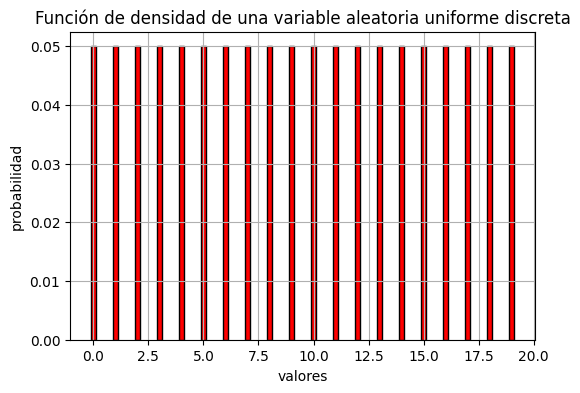

In [2]:
# Distribución uniforme discreta
min = 0
max = 20
x = np.arange(min, max)

# Vamos a crear la función de densidad (pmf (probability mass function))
pmf_unif = np.full_like(x, 1/(max-min), dtype=float) # crear un arreglo del mismo tamaño

#Graficamos la función de densidad
plt.figure(figsize=(6,4))
plt.bar(x, pmf_unif, width=0.2, color='r', edgecolor='black') # grafica de barras
plt.xlabel("valores")
plt.ylabel("probabilidad")
plt.title("Función de densidad de una variable aleatoria uniforme discreta")
plt.grid(True)
plt.show()

## Variable aleatoria Bernoulli con parámetro $p\in (0,1)$.

El modelo probabilístico Bernoulli se aplica a un experimento cuyo espacio muestral está constituido sólo por dos resultados posibles, éxito y fracaso:

Se considerará una v.a $X$ sobre el espacio muestral $$\Omega=\{\text{éxito, fracaso}\}$$
de tal forma que
* $X(\{\text{éxito}\}) = 1$
* $X(\{\text{fracaso}\}) = 0$

Las probabilidades asociadas a este modelo son:

* $\mathbb{P}(\{\text{éxito}\}) = p$
* $\mathbb{P}(\{\text{fracaso}\}) = 1-p$

donde $0<p<1$.


Entonces la función de densidad de masa de probabilidades de $X$ está dada por:

$$f_{X}(k)=\begin{cases}
p &\quad \text{si } k=1 \\
1-p &\quad \text{si } k=0
\end{cases}$$

**Notación:** $X\sim \text{Ber}(p)$.

Esta variable aleatoria es muy importante. En la practica es usada para modelar situaciones en las cuales hay dos posibles resultados como:
* el estado de un teléfono en un momento dado: libre u ocupado.
* una persona pueda estar enferma o sana de una determinada enfermedad.
* la preferencia de una persona, la cual puede estar a favor o en contra de un candidato determinado.

Mediante la combinación de variables aleatorias Bernoulli es posible construir otras variables aleatorias.

### Esperanza y Varianza

Si $X\sim \text{Ber}(p)$, entonces su esperanza es:
\begin{align*}
\mathbb{E}[X] = \sum_{k=0}^{1}kf_{X}(k) = 1\cdot p + 0\cdot (1-p) = p.
\end{align*}

Y su varianza se calcula usando,
$$\mathbb{E}[X^{2}] = \sum_{k=0}^{1}k^{2}f_{X}(k) = 1^{2}\cdot p + 0^{2}\cdot (1-p) = p.$$
Por lo tanto,
$$\text{Var}(X)=\mathbb{E}[X^{2}]-(\mathbb{E}[X])^{2} = p-p^{2} = p(1-p)$$



La función de densidad es: [0.4 0.6]


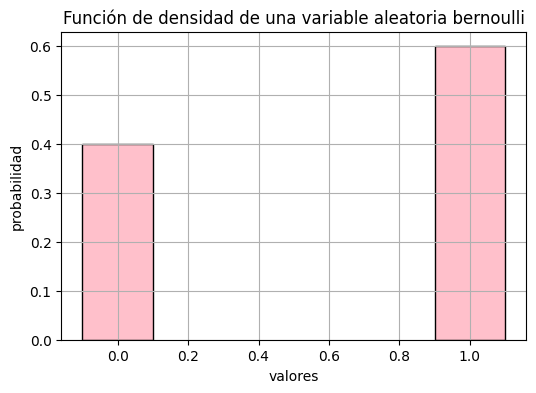

In [3]:
# Grafica de la distribución Bernoulli
# Definir mi probabilidad de éxito
p= 0.6 # éxito

# Defino los posibles valores de la variable aleatoria
x = [0,1]

# Calcular la función de masa de probabilidad
pmf_ber = bernoulli.pmf(x,p)

print("La función de densidad es:", pmf_ber)

# Graficamos la función de densidad
plt.figure(figsize=(6,4))
plt.bar(x, pmf_ber, width = 0.2, color = "pink", edgecolor = "k")
plt.xlabel("valores")
plt.ylabel("probabilidad")
plt.title("Función de densidad de una variable aleatoria bernoulli")
plt.grid(True)
plt.show()

In [4]:
media = bernoulli.mean(p) # esperanza
varianza = bernoulli.var(p) # varianza
print("La esperanza es:", media)
print("La varianza es:", varianza)

La esperanza es: 0.6
La varianza es: 0.24


## Variable aleatoria Binomial con parámetros $n$ y $p\in (0,1)$.

Decimos que una v.a $X$ tiene distribución binomial con párametros $n$ y $p$, si su función de densidad de masa de probabilidades está dada por:
$$\begin{equation*}
	f_{X}(k)= \mathbb{P}(X=k)= \begin{cases}
	\binom{n}{k}p^{k}(1-p)^{n-k} &\quad \text{si } k=0,1,\dots,n \\
	\qquad 0 &\quad \text{en otro caso}  
	\end{cases}
\end{equation*}$$
donde $n$ es un entero positivo y $0< p< 1$.

La esperanza de $X$ es:
\begin{align*}
\mathbb{E}[X]&= \sum_{k \mathop = 0}^n k \binom n k p^k (1-p)^{n - k}\\
&=\sum_{k \mathop = 1}^n k \binom n k p^k (1-p)^{n - k}\\
&= \sum_{k \mathop = 1}^n n \binom {n - 1} {k - 1} p^k (1-p)^{n - k}\\
&= n p \sum_{k \mathop = 1}^n \binom {n - 1} {k - 1} p^{k - 1} (1-p)^{( {n - 1}) - ( {k - 1}) }\\
&=n p \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j}\\
&=np
\end{align*}

Ahora,
\begin{align*}
\mathbb{E}[X^2]&= \sum_{k \mathop = 0}^n k^2 \binom n k p^k (1-p)^{n - k}\\
&=\sum_{k \mathop = 0}^n k n \binom {n - 1} {k - 1} p^k (1-p)^{n - k}\\
&= n p \sum_{k \mathop = 1}^n k \binom {n - 1} {k - 1} p^{k - 1} (1-p)^{({n - 1}) - ({k - 1}) }\\
&= n p \sum_{j \mathop = 0}^m ({j + 1}) \binom m j p^j (1-p)^{m - j}\\
&=n p \left( {\sum_{j \mathop = 0}^m j \binom m j p^j (1-p)^{m - j} + \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j} }\right)\\
&=n p \left( {\sum_{j \mathop = 0}^m m \binom {m - 1} {j - 1} p^j (1-p)^{m - j} + \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j} }\right)\\
&= n p \left( (n - 1) p \sum_{j \mathop = 1}^m \binom {m - 1}{j - 1} p^{j - 1} (1-p)^{( {m - 1}) - ({j - 1}) } + \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j}\right) \\
&= n p \left( (n - 1) p (p + (1-p))^{m - 1} + (p + (1-p))^m\right)\\
&= n p ((n - 1) p + 1)\\
&= (np)^2 +np(1-p),
\end{align*}

por lo que la varianza de $X$ es:
$$\text{Var}(X)=np(1-p).$$

**Ejemplo** Una moneda no justa se tira 6 veces, donde la probabilidad de obtener sol es de $0.3$.

Sea $X$ el número de veces que cae sol, entonces $X$ tiene una distribución binomial con parámetros $n=6$ y $p=0.3$. Por lo que
$$\begin{align*}
\mathbb{P}(X=2) &= \binom{6}{2}(0.3)^{2}(0.7)^{4}=0.3241 \\
\mathbb{P}(X=3) &= \binom{6}{3}(0.3)^{3}(0.7)^{3}=0.1852 \\
\mathbb{P}(1<X\le 5) &= \mathbb{P}(X=2)+\mathbb{P}(X=3)+\mathbb{P}(X=4)+\mathbb{P}(X=5) \\
			&= 0.3241 + 0.1852 + \binom{6}{4}(0.3)^{4}(0.7)^{2} + \binom{6}{5}(0.3)^{5}(0.7)^{1} \\
			&= 0.5093 + 0.0595 + 0.0102 = 0.579
\end{align*}$$

Note que la probabilidad $$\mathbb{P}(1<X\leq 5)=F_{X}(5)-F_{X}(1).$$

Usando el tributo `.cdf `, podemos calcualr la probabilidad anterior:

In [5]:
from scipy.stats import binom
# Proba de que haya 5 o menos éxitos en 6 ensayos
F5 = binom.cdf(5,6,0.3) # x=5, n=6, p=0.3

# Proba de que haya 1 o menos éxitos en 6 ensayos
F1 = binom.cdf(1,6,0.3) # x=1, n=6, p=0.3

In [6]:
F5-F1

np.float64(0.5790960000000003)

### Vamos a grafciar la función de densidad de una binomial

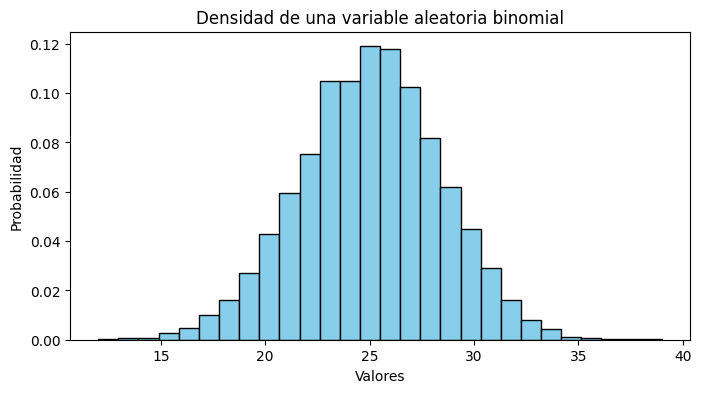

In [7]:
# Grafica de la distribución Binomial
# Parámetros
n = 50
p = 0.5

# Generamos numeros aleatorios con distribución binomial
binom_numeros = sps.binom.rvs(n,p,size = 10000)

# Creamos un histograma
plt.figure(figsize=(8,4))
plt.hist(
    binom_numeros,
    density = True, # normaliza para que sea función de densidad
    bins = len(np.unique(binom_numeros)), # numero de barras en el histograma
    color = "skyblue",
    edgecolor = 'k'
)
plt.xlabel('Valores')
plt.ylabel('Probabilidad')
plt.title('Densidad de una variable aleatoria binomial')
plt.show()

## Variable aleatoria Poisson

Es una distribución de probabilidad discreta que  sirve para calcular la probabilidad de que ocurra un determinado **número de eventos raros** durante un intervalo dado (puede ser de tiempo, longitud, área, etc.

Esta variable aleatoria toma los valores sobre el conjunto $\{0,1,2,\dots\}$ y tiene un parámetro $\lambda>0$, el cual representa el número de veces que se **espera** que ocurra un evento durante un intervalo dado.

La función de masa de probabilidades de una variable aleatoria Poisson, $X$, está dada por:
$$f_{X}(k)=\begin{cases}
	e^{-\lambda}\frac{\lambda^{k}}{k!} &\quad \text{si } k=0,1,2,\dots \\
	0 &\quad \text{en otro caso}  
\end{cases}$$

En efecto, es una función de masa de probabilidades debido a que
$$\begin{align*}
\sum_{k=0}^{\infty}e^{-\lambda}\frac{\lambda^{k}}{k!} &= e^{-\lambda}\sum_{k=0}^{\infty}\frac{\lambda^{k}}{k!} \\ &= e^{-\lambda}\underbrace{\left(1+\lambda+\frac{\lambda^{2}}{2!}+\frac{\lambda^{3}}{3!}+\cdots\right)}_{\text{desarrollo de Taylor de }e^{\lambda}} \\ &= e^{-\lambda}e^{\lambda}=1.
\end{align*}$$

Se tiene que $\mathbb{E}[X] = \lambda$ y $\text{Var}(X)= \lambda$.

**Aplicaciones**

**Ejemplo:** Supongamos que el número de accidentes que ocurre en un punto tiene una distribución Poisson con parámetro $\lambda=2$.
* ¿Cuál es la probabilidad de que en un día ocurran más de dos accidentes?
  $$
  \begin{align*}
	\mathbb{P}(X>2) &= 1-\mathbb{P}(X\le 2) \\ &=1-\left[\mathbb{P}(X=0)+\mathbb{P}(X=1)+\mathbb{P}(X=2)\right] \\ &= 1-\left[\frac{e^{-2}2^{0}}{0!}+\frac{e^{-2}2^{1}}{1!}+\frac{e^{-2}2^{2}}{2!}\right] \\ &= 1-e^{-2}\left[1+2+2\right] = 1-5e^{-2} = 0.3233
  \end{align*}
  $$

* ¿Cuál es la probabilidad de que en un día ocurran más de dos accidentes, sabiendo que ocurre por lo menos uno?
$$\begin{align*}
\mathbb{P}(X>2 \mid X\ge 1) = \frac{\mathbb{P}(X>2 \cap X\ge 1)}{\mathbb{P}(X\ge 1)} = \frac{\mathbb{P}(X>2)}{\mathbb{P}(X\ge 1)} = \frac{1-\mathbb{P}(X\leq 2)}{1-\mathbb{P}(X<1)} = \frac{1-5e^{-2}}{1-e^{-2}} = \frac{0.3233}{0.8646} = 0.3739
\end{align*}$$
ya que $\mathbb{P}(X\ge 1)=1-\mathbb{P}(X<1)=1-\mathbb{P}(X=0)=1-e^{-2}$

Ahora, vamos a calcular las probabilidades anteriores usando el atributo `.cdf`

In [8]:
from scipy.stats import poisson

In [9]:
# Sea el parametro lambda = 2
lamb = 2 # lambda es una palabra reservada

# Probabilidad de más de dos accidentes
prob_mas2 = 1 - poisson.cdf(2,lamb)

print("P(X>2) =",prob_mas2)
print("La probabilidad de que ocurran más de dos accidentes es: ",prob_mas2)

# Proba condicional
p_mas2_dado_uno = prob_mas2 / (1 - poisson.cdf(0,lamb))
p_mas2_dado_uno

print("P(X>2 | X >= 1) =",p_mas2_dado_uno)

P(X>2) = 0.3233235838169366
La probabilidad de que ocurran más de dos accidentes es:  0.3233235838169366
P(X>2 | X >= 1) = 0.37392942900133747


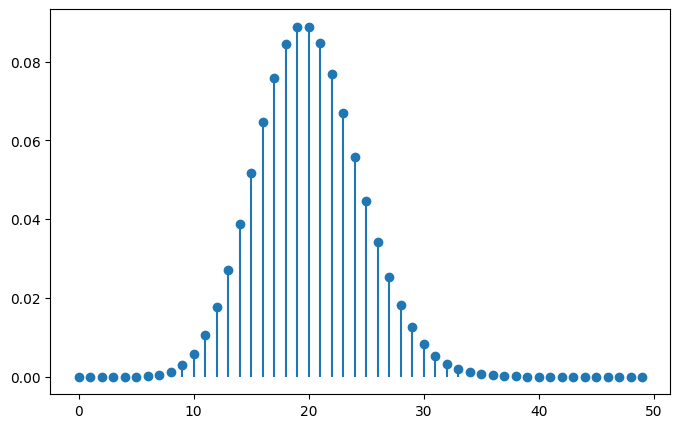

In [10]:
# Grafica de la densidad Poisson
x = np.arange(0,50)
y = poisson.pmf(x,20)

plt.figure(figsize=(8,5))
plt.vlines(x,0,y) #lineas verticales
plt.plot(x,y,'o')
plt.show()


## Aproximación de Poisson a la Binomial
La distribución de Poisson es una forma límite de la distribución binomial, es decir, es una buena aproximación cuando $n$ es suficientemente grande y $p$ suficientemente pequeña.

$\textbf{Teorema (Poisson).-}$ Sean $S_{n}\sim Bin(n,p_{n})$ bajo el regimen $$\lim_{n\to \infty}np_{n}=\lambda>0.$$
Consideremos la siguiente sucesión de números reales:
$$a_{j}(n,p_n)=\begin{cases}\binom{n}{j}(p_n)^{j}(1-p_{n})^{n-j} & j\leq n\\
0 & j\geq n+1\end{cases}$$

 Entonces,
 $$\lim_{n\to \infty}a_{j}(n,p_n)=a_{j}=e^{-\lambda}\frac{\lambda^{j}}{j!} \ \ \forall j\in \mathbb{N}.$$

 El teorema anterior implica que la distribución de Poisson ofrece un modelo probabilístico adecuado para todos aquellos experimentos aleatorios 	en los que las repeticiones son independientes unas de otras y en los 	que sólo hay dos posibles resultados: éxito o fracaso, con probabilidad de 	éxito pequeña, y en los que el interés se centra en conocer el número de éxitos obtenidos al realizar el experimento un número suficientemente grande de veces.

Empíricamente se ha establecido, que la aproximación se puede aplicar con seguridad si $n\ge100$, $p\le 0.01$ y $np \le20$.

**Ejemplo** Supongamos que la probabilidad de que un producto producido por cierta máquina es defectuoso es de $0.1$. ¿Cuál es la probabilidad de que un lote de 10 productos contenga a lo más un producto defectuoso?

Sea $X$ el número de productos defectuosos, y sabemos que $X$ tiene una distribución binomial con parámetros $n=10$ y $p=0.1$, entonces
\begin{align*}
\mathbb{P}(X\le 1) &= \mathbb{P}(X=0)+\mathbb{P}(X=1) \\ &= \binom{10}{0}(0.1)^{0}(0.9)^{10-0}+\binom{10}{1}(0.1)^{1}(0.9)^{10-1} \\ &= 0.7361
	\end{align*}

Ahora, con la distribución Poisson, tenemos que $\lambda=10(0.1)=1$, por lo que
$$\mathbb{P}(X\le 1) = \mathbb{P}(X=0)+\mathbb{P}(X=1) = \frac{e^{-1}1^{0}}{0!}+\frac{e^{-1}1^{1}}{1!} = e^{-1}+e^{-1} =0.7358$$

## Variable aleatoria Geométrica con parámetro $p\in (0,1)$.

Esta variable aleatoria cuenta el número de fracasos antes del primer éxito en ensayos bernoulli independientes con parámetro $0<p<1$, y su función de masa de probabilidades está dada por:
$$p_{X}(k)=\begin{cases}
	p(1-p)^{k-1} &\quad \text{si } k=1,2,\dots \\
	\qquad 0 &\quad \text{en otro caso}  
\end{cases}$$


Notación. $X\sim Geo(p)$

La cual es una función de densidad ya que:
* $0\le p_{X}(k)\le 1$ para toda $x$.
* $$\begin{align*}
    \sum_{k\in R_{X}}p_{X}(k) &= \sum_{k=1}^{\infty}(1-p)^{k-1}p \\
			&= p\sum_{y=0}^{\infty}(1-p)^{y} \\
			&= p\left(\frac{1}{1-(1-p)}\right) = 1
		\end{align*}$$

Si por el contrario queremos contar el número de éxitos antes del primer fracaso, tenemos que la función de está dada por:
	$$p_{X}(k)=\begin{cases}
		p^{k}(1-p) &\quad \text{si } k=0,1,2,\dots \\
		\qquad 0 &\quad \text{en otro caso}  
	\end{cases}$$

La esperanza de $X$ es:
$$ \mathbb{E}[X]=\frac{1}{p} $$
y
$$\mathbb{E}[X^2]=p\frac{2}{p^3}-\frac{1}{p}=\frac{2}{p^2}-\frac{1}{p}.$$

Por lo tanto,
$$\text{Var}(X)=\frac{2}{p^2}-\frac{1}{p}-\frac{1}{p^2}=\frac{1-p}{p^2}.$$

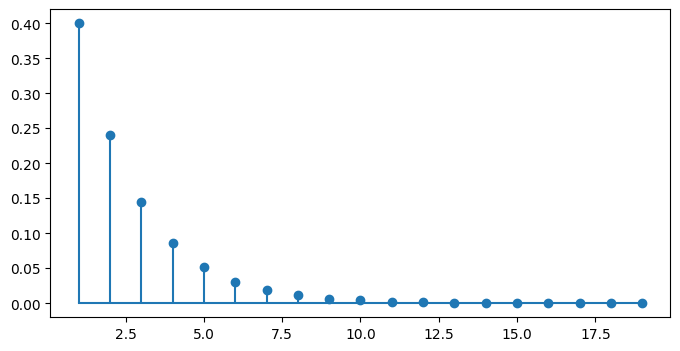

In [11]:
# Vamos a graficar la función de densidad de v.a. geometrica

from scipy.stats import geom

# Parametro
p = 0.4

# valores posibles
x = np.arange(1,20)

pmf_geo = geom.pmf(x,p)

plt.figure(figsize=(8,4))
plt.stem(x,pmf_geo, basefmt="") # barras verticales
plt.show()

# Variable Aleatoria Binomial Negativa $X \sim \text{BN}(r, p)$

La distribución **Binomial Negativa** describe procesos donde el número de éxitos está predeterminado ($r$), y nuestra incertidumbre recae sobre cuántos intentos totales ($X$) necesitaremos realizar para alcanzar dicha meta.

Supongamos que se realizan ensayos independientes, cada uno con probabilidad $0<p<1$ de ser un éxito, hasta obtener un total de $r$ éxitos acumulados. Sea $X$ el número de ensayos que se requieren, entonces la probabilidad de que el éxito número $r$ ocurra exactamente en el ensayo $k$ es:

$$f_{X}(k) = \binom{k-1}{r-1} p^r (1-p)^{k-r}$$

Donde:
- El valor de $k$ pertenece al conjunto $\{r, r+1, r+2, \dots\}$.
- El parámetro de Forma ($r$): representa el número de éxitos acumulados que deseamos obtener ($r \geq 1$).
- El parámetro de Intensidad ($p$): es la probabilidad de éxito en cada ensayo independiente ($0 < p < 1$).

El valor promedio esperado de ensayos totales es:
$$\mathbb{E}[X] = \frac{r}{p}$$
 Y la varianza mide la dispersión de los ensayos necesarios:
$$\text{Var}[X] = \frac{r(1-p)}{p^2}$$

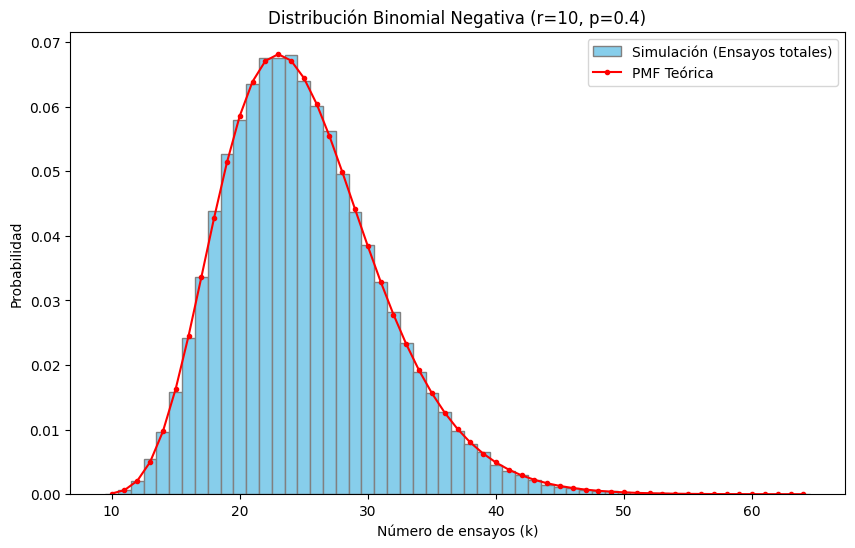

In [12]:
import numpy as np
import scipy.stats as sps
import matplotlib.pyplot as plt
import random

r = 10
p = 0.4
s = 100000

np.random.seed(3)

# 1. Generamos los fracasos y SUMAMOS r para obtener ensayos totales
nbinom_fracasos = sps.nbinom.rvs(r, p, size=s)
nbinom_ensayos = nbinom_fracasos + r

# 2. Creamos el histograma
plt.figure(figsize=(10,6))
plt.hist(
    nbinom_ensayos,
    density=True,
    bins=np.arange(r, np.max(nbinom_ensayos) + 1) - 0.5, # Centramos las barras
    color="skyblue",
    edgecolor="grey",
    label='Simulación (Ensayos totales)'
)

# 3. Superponemos la PMF teórica para validar
x_teorico = np.arange(r, np.max(nbinom_ensayos))
# Usamos x_teorico - r porque la PMF de scipy pide fracasos
pmf_teorica = sps.nbinom.pmf(x_teorico - r, r, p)

plt.plot(x_teorico, pmf_teorica, 'ro-', markersize=3, label='PMF Teórica')

plt.xlabel('Número de ensayos (k)')
plt.ylabel('Probabilidad')
plt.title(f'Distribución Binomial Negativa (r={r}, p={p})')
plt.legend()
plt.show()

## Variable aleatoria Hipergeométrica con parámetros $n,N,m$.

Supongamos que se elige, **sin reemplazo**, una muestra de tamaño $n$ de una urna que contiene $N$ bolas, de las cuales $m$ son rojas y $N-m$ son verdes. Sea $X$ el número de bolas rojas seleccionadas, entonces su función de masa de probabilidades está dada por:
$$f_{X}(i)=
	\frac{\binom{m}{i}\binom{N-m}{n-i}}{\binom{N}{n}} \quad \text{si } i=0,1,\dots, n  
$$
Donde
- Los valores posibles de $X$ son
$$ i=\max\{0,n-(N-m)\},\dots,\min\{n,m\}. $$

Notación. $X\sim \text{Hiper}(n,N,m)$.

Se tiene que
$$\mathbb{E}[X]=\frac{nm}{N}$$
y
$$\text{Var}[X]=\frac{nm}{N}\left[\frac{(n-1)(m-1)}{N-1}+1-\frac{nm}{N} \right].$$

Equivalentemente,

$$
\mathrm{Var}(X)=n\frac{m}{N}\left(1-\frac{m}{N}\right)\frac{N-n}{N-1}.
$$

**Nota.** Si $i\leq n$ y $X\sim \text{Hiper}(n,N,m)$, con $p=\frac{m}{N}$ y $m,N$ son muy grandes con respecto a $n$ e $i$, entonces
$$\mathbb{P}(X=i)\approx \binom{n}{i}p^{i}(1-p)^{n-i}.$$

Es decir, en poblaciones muy grandes, la distribución hipergeométrica puede aproximarse por una distribución binomial.